In [52]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
    

In [53]:
train = pd.read_csv('/Users/maidaraza/Desktop/Data Analytics Projects/2026-10-06 - Customer Churn Analysis/Data & Resources/Data/Train Data.csv')

In [54]:
# Dropping columns not used for prediction
train = train.drop(
    columns=['customer_id', 'churn_category', 'churn_reason']
)

# List of categorical columns to encode
columns_to_encode = [
    'gender',
    'married',
    'state',
    'value_deal',
    'phone_service',
    'multiple_lines',
    'internet_service',
    'internet_type',
    'online_security',
    'online_backup',
    'device_protection_plan',
    'premium_support',
    'streaming_tv',
    'streaming_movies',
    'streaming_music',
    'unlimited_data',
    'contract',
    'paperless_billing',
    'payment_method'
]

# Encode categorical variables except the target variable
label_encoders = {}

for column in columns_to_encode:
    label_encoders[column] = LabelEncoder()
    train[column] = label_encoders[column].fit_transform(
        train[column]
    )
    
# Manually encoding the target variable 'Customer_Status'
train['customer_status'] = train['customer_status'].map({'Stayed': 0, 'Churned':1})

# Split data into features and target

X = train.drop('customer_status', axis = 1)
y = train['customer_status']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)


In [55]:
# Train RF Model

# Initialize the classifier
rf_model = RandomForestClassifier(n_estimators = 100, random_state = 42)

rf_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

Confusion Matrix:
[[786  60]
 [124 232]]

Classification Report
              precision    recall  f1-score   support

           0       0.86      0.93      0.90       846
           1       0.79      0.65      0.72       356

    accuracy                           0.85      1202
   macro avg       0.83      0.79      0.81      1202
weighted avg       0.84      0.85      0.84      1202



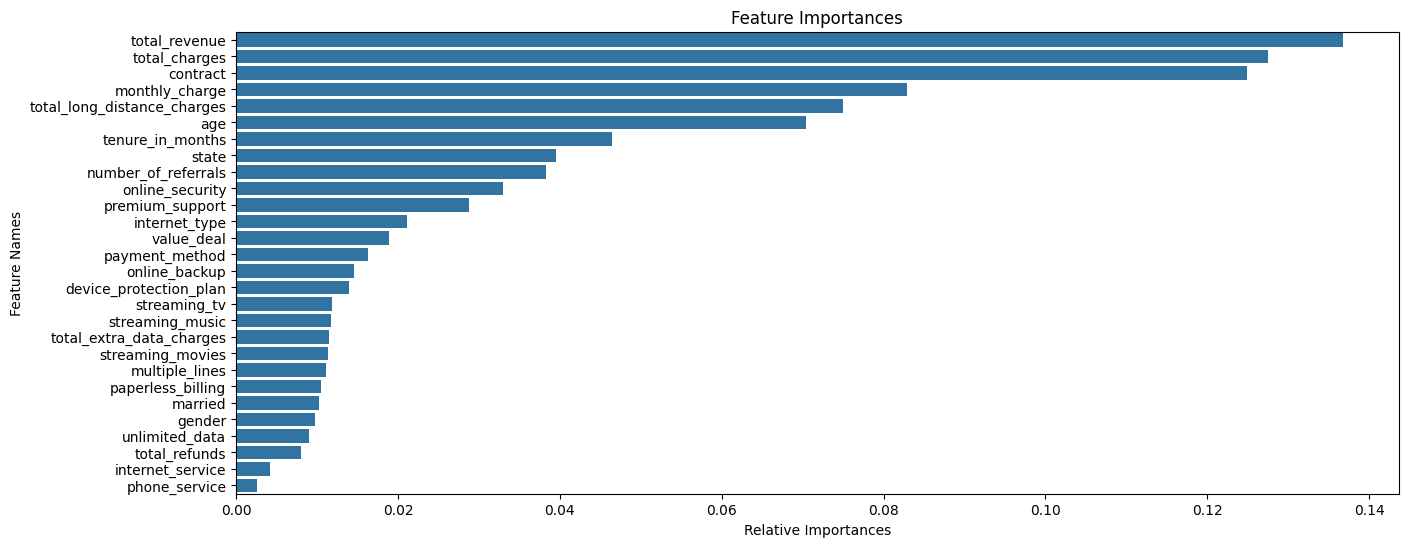

In [56]:
# Evaluating the model
y_pred = rf_model.predict(X_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report")
print(classification_report(y_test, y_pred))

# Feature selection using feature importance
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(15,6))
sns.barplot(x=importances[indices], y =X.columns[indices])
plt.title("Feature Importances")
plt.xlabel("Relative Importances")
plt.ylabel("Feature Names")
plt.show()



### Insights:
* There is a class imbalance.  The model is better at predicting the customers who stay. This could be because of the class imbalance.  Should we balance the classes, there is a chance that the overall models accuracy will go above 84%
* Having a lot of features risks overtraining the model because the model starts capturing outliers and behaviors that are not relevant in predicting the churn. We also notice that there are features that have lower importance in predicting churn.  The cadence is to drop the features with an importance <= 0.01. 

In [58]:
# Read the data from the specified sheet into a pandas DataFrame
new_data = pd.read_csv('/Users/maidaraza/Desktop/Data Analytics Projects/2026-10-06 - Customer Churn Analysis/Data & Resources/Data/Prediction Data.csv')

# Display the first few rows of the fetched data
print(new_data.head())

# Retain the original DataFrame to preserve unencoded columns
original_data = new_data.copy()

# Retain the Customer_ID column
customer_ids = new_data['customer_id']

# Drop columns that won't be used for prediction in the encoded DataFrame
new_data = new_data.drop(['customer_id', 'customer_status', 'churn_category', 'churn_reason'], axis=1)

# Encode categorical variables using the saved label encoders
for column in new_data.select_dtypes(include=['object']).columns:
    new_data[column] = label_encoders[column].transform(new_data[column])

# Make predictions
new_predictions = rf_model.predict(new_data)

# Add predictions to the original DataFrame
original_data['customer_status_predicted'] = new_predictions

# Filter the DataFrame to include only records predicted as "Churned"
original_data = original_data[original_data['customer_status_predicted'] == 1]

# Save the results
original_data.to_csv(r"/Users/maidaraza/Desktop/Data Analytics Projects/2026-10-06 - Customer Churn Analysis/Data & Resources/Data/Output\Predictions.csv", index=False)


  customer_id  gender  age married           state  number_of_referrals  \
0   93520-GUJ  Female   67      No         Gujarat                   13   
1   57256-BIH  Female   18      No           Bihar                    9   
2   72357-MAD  Female   53      No  Madhya Pradesh                   14   
3   66612-KAR  Female   58     Yes       Karnataka                   11   
4   22119-WES    Male   31     Yes     West Bengal                    5   

   tenure_in_months value_deal phone_service multiple_lines  ...  \
0                19     Deal 5           Yes            Yes  ...   
1                 7        NaN           Yes             No  ...   
2                12     Deal 5           Yes             No  ...   
3                18        NaN           Yes             No  ...   
4                 5        NaN           Yes             No  ...   

    payment_method monthly_charge total_charges total_refunds  \
0  Bank Withdrawal          72.10          72.1           0.0   
1      Cre